# BGS+: what is in the data, and how the GeoRDF2Vec repo reads it

Exploratory analysis of our second dataset, written to mirror `dmg777k_eda.ipynb` so the two can be read side by side. It answers the same three questions:

1. **What does BGS+ contain?** (Sections 1, 3)
2. **What does the repository's code do to it, and what follows?** (Section 2)
3. **Does the data support our planned contributions:** relation-aware flooding, better aggregation of inherited geometries, adaptive walk length and locality-aware walks? (Section 4)

**To run it:** `uv sync`, `uv run scripts/download_bgs.py`, `uv run python data_preparation/bgs_data_prep.py`, then run this notebook top to bottom. It takes about 4 minutes and about 4 GB of memory. Figures are exported to `reports/figures/bgs_*`. **Labels from the test split are never used**: every comparison uses cross-validation over the training and validation units only (117 of 146).

## Main outcomes

- **This is a different kind of test from dmg777k.** The task is to tell rock units laid down by rivers (FLUV) from those laid down by ice (GLACI). There are only 146 labelled units, but location is a **strong** signal. Coordinates alone reach macro F1 0.87 against 0.47 for shuffled labels; in dmg777k the same test gave 0.26 against 0.13.
- **The labelled units have no geometry of their own.** 97 get a location through their *stratotype*, the reference site where the unit is defined. The other 49 get one only through the `skos:Concept` class hub, which hands them **the centroid of all 48,603 geometries**: a single point in southern Scotland. Overall, 50.3% of all nodes end up there, against 18.5% in dmg777k.
- **Relation-aware flooding helps, and we can measure it without training anything.** Dropping schema and attribute relations brings the units with hidden stratotypes from a median of 389 km off to 59 km off. It also raises the location-only classifier from macro F1 0.72 to 0.78.
- **The repo needs one new preparation step, otherwise it silently stops being geographic.** Geometries are in British National Grid metres. The repo would read them as degrees, every distance would become 0, and GeoRDF2Vec would reduce to plain RDF2Vec. `bgs_data_prep.py` reprojects them.
- **Walk length behaves as in dmg777k when edges are followed forwards** (about 1.7 steps of 8). If walks may go both ways, they always reach full length and the weights keep them 28–53 km closer to the start. Most of them pass through the national-centroid hub, though.


In [1]:
import sys
import warnings
from collections import Counter

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from scipy.stats import mannwhitneyu
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

from eda import plots, spatial as sp
from eda.bgs import data as bgs
from eda.graph import build_graph
from eda.paths import REPO_ROOT

sys.path.insert(0, str(REPO_ROOT))
from geo_rdf2vec import GeoRDF2Vec

plots.apply_style()
pd.set_option("display.max_colwidth", 70, "display.width", 160)
warnings.filterwarnings("ignore", message="Latitude normalization")   # geopy, triggered on purpose in Section 2

def short(iri: str) -> str:
    """Last part of an IRI, for readable labels."""
    return str(iri).rstrip("/").rsplit("/", 1)[-1].rsplit("#", 1)[-1]

def save(fig, name):
    plots.save(fig, f"bgs_{name}")

triples = bgs.load_triples()
kinds = bgs.load_node_kinds()
labels = bgs.load_labels()
graph = build_graph(triples)
names = graph.vs["name"]
vertex_of = {name: i for i, name in enumerate(names)}
node_kind = pd.Series(names).map(kinds).map(bgs.kind_group).to_numpy()
is_entity = node_kind == "Entity (IRI)"
labelled_vertices = np.array([vertex_of[n] for n in labels["node"]])
print(f"{len(triples):,} triples, {triples['predicate'].nunique()} relations, {len(labels)} labelled rock units")
print(f"{graph.vcount():,} nodes and {graph.ecount():,} edges in the graph")

916,199 triples, 103 relations, 146 labelled rock units
273,963 nodes and 916,199 edges in the graph


## 1. What the data is

BGS+ describes rocks of Great Britain as a knowledge graph built from two sources of the British Geological Survey: the **Lexicon of Named Rock Units**, a dictionary of rock formations with their ages, rock types and reference sites, and the **1:625,000 digital geological map**, whose units, dykes and faults are polygons and lines. It was first used for machine learning by de Vries (2013), became a standard benchmark (R-GCN, RDF2Vec), and was republished with datatype declarations as BGS+ by Wilcke et al. (2020). The task is **node classification**: predict how a rock unit formed.

| Term | Meaning here |
|---|---|
| **Named rock unit** | An entry of the Lexicon, such as *Leen Sand And Gravel*. These are the labelled nodes. |
| **Lithogenesis** | How a rock formed. The target, with two classes: **FLUV** (fluvial, laid down by rivers) and **GLACI** (glacial, laid down by ice). |
| **Superficial deposit** | Loose, young (Quaternary) sediment lying on top of the bedrock. 144 of the 146 labelled units are of this kind. |
| **Stratotype** | The reference site where a unit is defined and can be seen. It has its own point and footprint. |
| **Map unit** | A polygon of the 1:625k geological map. It links to the Lexicon entry it shows through `hasLexicon`. |
| **BNG** | British National Grid (EPSG:27700), the British coordinate system in metres. All raw geometries use it. |

Terms shared with the dmg777k notebook (triple, node, entity, literal, WKT, WGS84) mean the same here.

These are all the facts about one labelled unit (one example shown per relation):

In [2]:
example = "http://data.bgs.ac.uk/id/Lexicon/NamedRockUnit/LNSG"
rows = triples[triples["subject"] == example].copy()
rows["predicate"] = rows["predicate"].map(short)
rows["object"] = rows["object"].str.slice(0, 70)
rows[["predicate", "object"]].groupby("predicate", as_index=False).first()

,predicate,object
0,altLabel,LNSG
1,broader,http://data.bgs.ac.uk/id/Lexicon/NamedRockUnit/__NE__
2,hasCurrentStatus,http://data.bgs.ac.uk/ref/CurrentStatus/CURRENT
3,hasDefinitionStatus,http://data.bgs.ac.uk/id/Lexicon/DefinitionStatus/INDEX
4,hasFormality,FORMAL
5,hasLithologyComponent,http://data.bgs.ac.uk/id/Lexicon/LithologyComponent/LNSG_GRAV
6,hasLithologyDescription,"Sand and gravel, locally with lenses of silt, clay or peat. [Gener..."
7,hasOldestAge,http://data.bgs.ac.uk/id/Geochronology/Division/Q1
8,hasPredominantAge,http://data.bgs.ac.uk/id/Geochronology/Division/Q1
9,hasRevisionNumber,0


**Reading this:** a rock unit has about twenty kinds of fact: names, ages, a status, its lithology components and its place in the Lexicon hierarchy (`broader`). Its location is not stored on it. This unit has no stratotype either, so, as Section 4 shows, flooding can only reach it through general nodes such as `skos:Concept`.

### What kinds of node exist?

Unlike KGBench, BGS+ is plain N-Triples: a literal's datatype or language tag is part of the file. `bgs_data_prep.py` keeps it in `node_kinds.csv` for this analysis. The repo itself drops it, as it does for dmg777k.

Triples whose subject is not an entity: 0


Repeated identical triples: 0


Node pairs joined by more than one relation: 95,303
Entity types: {'Lexicon/LithologyComponent': 22302, 'Lexicon/NamedRockUnit': 17942, 'Lexicon/EquivalentName': 14174, 'Lexicon/SourceInfo': 12901, '625KGeologyMap/Unit': 11244, 'Lexicon/Stratotype': 5534, 'other': 5493, 'EarthMaterialClass/RockName': 3618}


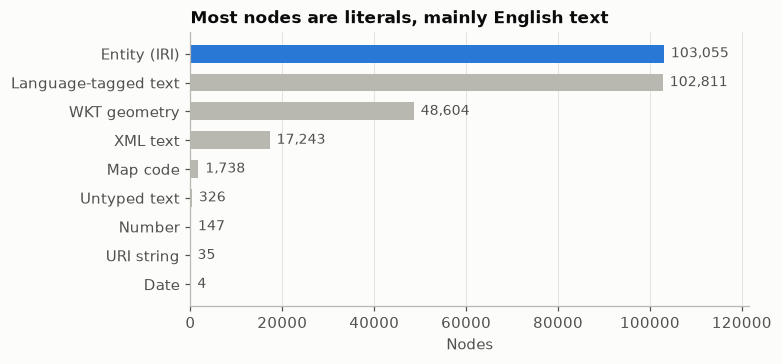

,nodes,share
Entity (IRI),103055,37.6%
Language-tagged text,102811,37.5%
WKT geometry,48604,17.7%
XML text,17243,6.3%
Map code,1738,0.6%
Untyped text,326,0.1%
Number,147,0.1%
URI string,35,0.0%
Date,4,0.0%


In [3]:
composition = pd.Series(node_kind).value_counts().rename("nodes").to_frame()
composition["share"] = (composition["nodes"] / graph.vcount()).map("{:.1%}".format)
print("Triples whose subject is not an entity:", (~pd.Series(triples["subject"].unique()).map(kinds).eq("entity")).sum())
print("Repeated identical triples:", triples.duplicated().sum())
print("Node pairs joined by more than one relation:", f"{triples[['subject', 'object']].value_counts().gt(1).sum():,}")
print("Entity types:", pd.Series(names)[is_entity].map(bgs.entity_type).value_counts().head(8).to_dict())

ordered = composition["nodes"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
colours = [plots.BLUE if kind == "Entity (IRI)" else plots.NEUTRAL for kind in ordered.index]
ax.barh(ordered.index, ordered.values, color=colours, height=0.62)
for yy, value in enumerate(ordered.values):
    ax.text(value + 1500, yy, f"{value:,}", va="center", color=plots.MUTED, fontsize=9)
ax.set(title="Most nodes are literals, mainly English text", xlabel="Nodes")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, ordered.max() * 1.18)
save(fig, "node_composition")
plt.show()
composition

**Interpretation:** 62.4% of nodes are literals, and most of those are English text (names, descriptions) or WKT geometries. There are no images. Every subject is an entity, so literals are again end points of the graph. There are no repeated triples, but 95,303 pairs of nodes are joined by more than one relation. Lexicon entries make up most entities; the map contributes 11,244 units plus dykes and faults.

## 2. How the repo parses the data, and what follows

The pipeline is the same as for dmg777k, so this section only reports what differs. The first step is new: the repo has no preparation script for BGS+, so we wrote `data_preparation/bgs_data_prep.py`. It parses the N-Triples, keeps literals as their plain text, and converts all geometries from British National Grid to WGS84, as `dmg_data_prep.py` does for the 371 RD New geometries of dmg777k. The 146 label triples are not in the main file, so the graph has 916,199 triples rather than the 916,345 the dataset README lists.

### Steps 1–2: from files to a graph

`geo_rdf2vec.py` builds the graph from node text, so two nodes with the same text become one node.

In [4]:
loops = np.array(graph.is_loop())
print("Self-loops:", f"{loops.sum():,}", pd.Series(graph.es["predicate"])[loops].map(short).value_counts().to_dict())
print("Labelled units with a self-loop:", f"{np.isin(labelled_vertices, [graph.es[int(e)].source for e in np.flatnonzero(loops)]).sum()} of {len(labels)}")
literal_objects = set(triples.loc[~triples["object"].map(kinds).eq("entity"), "object"])
print("Texts used both as an entity and as a literal:", f"{len(literal_objects & set(triples['subject'])):,}")
print(f"Average degree: {2 * graph.ecount() / graph.vcount():.4f}")

Self-loops: 58,689 {'identifier': 58689}
Labelled units with a self-loop: 146 of 146


Texts used both as an entity and as a literal: 0
Average degree: 6.6885


**Interpretation:**

- **Merging gives every entity with an `identifier` a self-loop: 58,689 in total, including all 146 labelled units.** The `identifier` literal has the same text as the entity's own IRI. This is the same effect as `seeAlso` in dmg777k, about seven times larger, and it brings the same predicate-shift problem in the walk text.
- No other text is used both as an entity and as a literal, so nothing else merges across kinds. Literals with the same text and different datatypes do merge (such as the number `0` and a text `0`), as in dmg777k.

### Step 3a: the coordinate system

BGS+ stores coordinates in metres, such as `POINT (491414.5 426600.7)`, without saying which system they are in. The repo assumes every WKT is longitude and latitude in degrees. What happens if the raw file is used directly?

In [5]:
raw_a, raw_b = shapely.Point(491414.5, 426600.7), shapely.Point(256689.5, 940395.5)   # British National Grid metres
repo = object.__new__(GeoRDF2Vec)   # only the distance methods are used, no training
to_wgs = lambda p: shapely.from_wkt(sp.extract_wkt(shapely.to_wkt(p)))
from pyproj import Transformer
tr = Transformer.from_crs(27700, 4326, always_xy=True)
wgs_a, wgs_b = (shapely.Point(*tr.transform(p.x, p.y)) for p in (raw_a, raw_b))
print("Repo distance on raw BNG metres:  ", repo.spatial_distance_calculation([raw_a], [raw_b]), "km")
try:
    repo.spatial_weighting_calculation([raw_a], [raw_b])
except ValueError as error:
    print("Repo 'naive' weighting on raw metres raises:", str(error)[:70])
print("After reprojection, as written:   ", round(repo.spatial_distance_calculation([wgs_a], [wgs_b]), 1), "km (axis swap included)")
print("After reprojection, correct order:", round(float(sp.geodesic_km(wgs_a.x, wgs_a.y, wgs_b.x, wgs_b.y)), 1), "km")

Repo distance on raw BNG metres:   0 km
Repo 'naive' weighting on raw metres raises: Latitude must be in the [-90; 90] range.
After reprojection, as written:    664.3 km (axis swap included)
After reprojection, correct order: 565.0 km


**Interpretation:** without reprojection, **GeoRDF2Vec silently stops being geographic**. geopy rejects latitudes such as 426,600, the repo's `spatial_distance_calculation` catches the error and returns 0, so every edge has distance 0 and weight 1, which is exactly plain RDF2Vec. The `naive` weighting has no such catch and crashes instead. After reprojection, the repo's axis swap still applies: at British latitudes it overstates east–west distances even more than in the Netherlands (see Step 5).

### Step 3: which nodes count as geographic

In [6]:
is_wkt = pd.Series(names).map(kinds).eq(bgs.WKT_KIND).to_numpy()
repo_seeds = sp.find_wkt_nodes(names, sp.REPO_WKT_PATTERN)
print(f"WKT-typed nodes: {is_wkt.sum():,}   recognised by the repo: {len(repo_seeds):,}   recognised but not WKT-typed: {(~is_wkt[repo_seeds]).sum()}")
missed = [names[i] for i in np.setdiff1d(np.flatnonzero(is_wkt), repo_seeds)]
print("WKT nodes the repo misses:", missed)
seeds = repo_seeds
geometries = sp.parse_geometries(names[i] for i in seeds)

WKT-typed nodes: 48,604   recognised by the repo: 48,603   recognised but not WKT-typed: 0


WKT nodes the repo misses: ['POLYGON EMPTY']


**Interpretation:** the repo's regular expression finds every geometry here. BGS+ always writes the type in capitals, so the `Point` spelling problem of dmg777k does not occur. The only WKT it skips is `POLYGON EMPTY`, used by two stratotypes, which carries no location anyway. The geometry nodes are also clean in another way: none of the 48,603 matches is a piece of ordinary text.

### Step 4: flooding

In [7]:
flooded = sp.flood(graph, seeds)
x, y = sp.node_centroids(flooded, geometries)
print(f"Nodes given a location: {(flooded.hops >= 0).sum():,} of {graph.vcount():,}")

Nodes given a location: 273,963 of 273,963


**Interpretation:** the graph is connected, so every node gets a location. Section 4 examines how meaningful those locations are.

### Step 5: distances and weights

In [8]:
from geopy.distance import geodesic
swap_check = pd.DataFrame(
    {
        "Repo call, lon-lat order (km)": [geodesic([(-1.5, 54.0)], [(-0.5, 54.0)]).km, geodesic([(-1.5, 54.0)], [(-1.5, 55.0)]).km],
        "Correct lat-lon order (km)": [geodesic((54.0, -1.5), (54.0, -0.5)).km, geodesic((54.0, -1.5), (55.0, -1.5)).km],
    },
    index=["One degree east at 54°N", "One degree north"],
).round(1)
display(swap_check)

distance_repo = sp.edge_distances(graph, x, y, swap_axes=True)
distance_true = sp.edge_distances(graph, x, y, swap_axes=False)
weight_repo = sp.repo_minmax_weights(graph, distance_repo)
edges = np.array(graph.get_edgelist())
pd.Series(
    {
        "Mean edge distance, repo (km)": round(distance_repo.mean(), 2),
        "Mean edge distance, correct axes (km)": round(distance_true.mean(), 2),
        "Mean edge weight, repo": round(weight_repo.mean(), 3),
        "Edges with distance 0": f"{(distance_true == 0).mean():.1%}",
        "Edges with weight exactly 1": f"{(weight_repo == 1).mean():.1%}",
    }
).to_frame("Value")

,"Repo call, lon-lat order (km)",Correct lat-lon order (km)
One degree east at 54°N,110.6,65.6
One degree north,111.3,111.3


,Value
"Mean edge distance, repo (km)",107.97
"Mean edge distance, correct axes (km)",95.43
"Mean edge weight, repo",0.816
Edges with distance 0,52.5%
Edges with weight exactly 1,55.6%


**Interpretation:**

- **The axis swap distorts more here than in dmg777k.** At 54°N, one degree east counts as 110.6 km instead of 65.6 km, so east–west edges look about 70% longer (60% in the Netherlands). The mean edge length goes from 95.4 km to 108.0 km.
- **Edges are long.** The mean edge is 95 km, against 37 km in dmg777k. Great Britain is larger, but the main reason is the national-centroid nodes of Section 4: an edge between a unit and such a node spans hundreds of kilometres.
- **More than half the edges carry no spatial information.** 52.5% have distance 0, and 55.6% have weight exactly 1. The mean weight is 0.816. The paper reports no figures for BGS+, so there is nothing to compare these with.

### Steps 6–7: walks and word2vec

These run the same code as for dmg777k, so the findings there apply unchanged: walks follow outgoing edges only and stop at a literal, word2vec as committed trains on nothing, and self-loops shift the predicates in the walk text. Section 4 measures walk length on this graph.

### Summary: what differs from dmg777k in the repo's handling

| Step | What happens on BGS+ | Effect | For our baseline |
|---|---|---|---|
| Preparation | No script in the repo; coordinates are BNG metres | Without reprojection, all distances are 0 and GeoRDF2Vec equals RDF2Vec | **Must use** `bgs_data_prep.py` |
| Parsing | `identifier` literal merges with its entity | 58,689 self-loops, on all labelled units | Keep, report |
| Geometry detection | All capital-letter WKT | Nothing missed except `POLYGON EMPTY` | Keep |
| Distance | Longitude and latitude swapped | East–west edges about 70% too long | Keep, and test the fix as a variant |
| Walks, word2vec | Same code as dmg777k | Same issues | As for dmg777k |


## 3. Basic exploratory analysis

### Degree and hubs

As for dmg777k, all analysis from here on uses the repo's merged graph.

Graph: 103,055 entities and 170,908 literals
Nodes with no outgoing edge: 190,440 (69.5%)
Median total degree: 1; maximum: 83,024


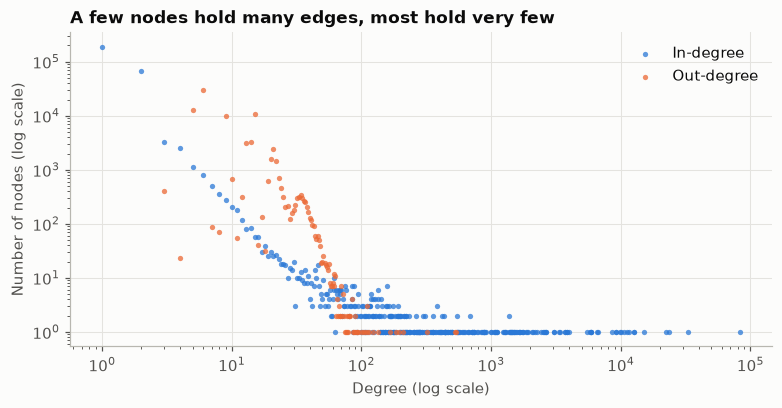

,node,kind,in,out,total
0,http://www.w3.org/2004/02/skos/core#Concept,Entity (IRI),83024,0,83024
1,Not Entered,Language-tagged text,33139,0,33139
2,http://data.bgs.ac.uk/ref/Lexicon/NamedRockUnit,Entity (IRI),23395,9,23404
3,http://data.bgs.ac.uk/ref/625KGeologyMap/Unit,Entity (IRI),22488,5,22493
4,http://www.w3.org/1999/02/22-rdf-syntax-ns#nil,Entity (IRI),15235,0,15235
5,http://data.bgs.ac.uk/ref/CurrentStatus/CURRENT,Entity (IRI),12759,0,12759
6,http://data.bgs.ac.uk/id/EarthMaterialClass/ComponentRank/MAIN,Entity (IRI),12729,0,12729
7,http://data.bgs.ac.uk/id/Lexicon/ShapeType/NotEntered,Entity (IRI),11676,6,11682
8,http://data.bgs.ac.uk/id/onshoreOffshore/ONSHORE,Entity (IRI),11101,0,11101
9,FORMAL,Untyped text,10559,0,10559


In [9]:
total_degree = np.array(graph.degree(mode="all"))
out_degree, in_degree = np.array(graph.outdegree()), np.array(graph.indegree())
print(f"Graph: {is_entity.sum():,} entities and {(~is_entity).sum():,} literals")
print(f"Nodes with no outgoing edge: {(out_degree == 0).sum():,} ({(out_degree == 0).mean():.1%})")
print(f"Median total degree: {np.median(total_degree):.0f}; maximum: {total_degree.max():,}")

fig, ax = plt.subplots(figsize=(7, 3.6))
for values, colour, title in ((in_degree, plots.BLUE, "In-degree"), (out_degree, plots.ORANGE, "Out-degree")):
    degree, count = np.unique(values[values > 0], return_counts=True)
    ax.scatter(degree, count, s=12, color=colour, label=title, alpha=0.75, linewidths=0)
ax.set(xscale="log", yscale="log", xlabel="Degree (log scale)", ylabel="Number of nodes (log scale)",
       title="A few nodes hold many edges, most hold very few")
ax.legend()
save(fig, "degree_distribution")
plt.show()

hubs = pd.DataFrame({"node": names, "kind": node_kind, "in": in_degree, "out": out_degree, "total": total_degree})
hubs["node"] = hubs["node"].str.slice(0, 62)
hubs.nlargest(10, "total").reset_index(drop=True)

**Interpretation:** the distribution is heavy-tailed. The median node has one edge, while `skos:Concept` has 83,024, because almost every Lexicon and map entity is typed as one. 69.5% of nodes have no outgoing edge, more than in dmg777k (58.5%). The other hubs are again schema nodes and shared values rather than places: the class of rock units, the empty list `rdf:nil`, the status `CURRENT`, and the literal `Not Entered`, which stands for a missing value in 33,139 places. Section 4 shows that these hubs decide where half of all nodes end up.

### Relations

103 relations; the top 5 cover 29.6% of edges
Relations with fewer than 100 edges: 18


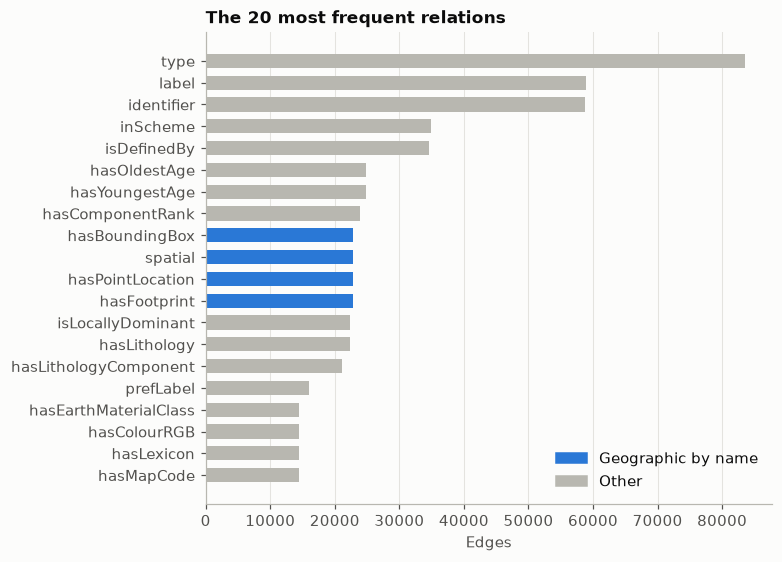

In [10]:
relation_counts = triples["predicate"].value_counts()
top = relation_counts.head(20).sort_values()
print(f"{len(relation_counts)} relations; the top 5 cover {relation_counts.head(5).sum() / len(triples):.1%} of edges")
print("Relations with fewer than 100 edges:", (relation_counts < 100).sum())
spatial_terms = ("Spatial", "spatial", "Stratotype", "Location", "Geographical")
colours = [plots.BLUE if any(term in iri for term in spatial_terms) else plots.NEUTRAL for iri in top.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh([short(iri) for iri in top.index], top.values, color=colours, height=0.65)
ax.set(xlabel="Edges", title="The 20 most frequent relations")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=plots.BLUE), plt.Rectangle((0, 0), 1, 1, color=plots.NEUTRAL)],
          labels=["Geographic by name", "Other"], loc="lower right")
save(fig, "relation_frequency")
plt.show()

**Interpretation:** usage is spread more evenly than in dmg777k: the top 5 of 103 relations cover 29.6% of edges, and 18 relations have fewer than 100 edges. The frequent ones are bookkeeping: `type`, labels, identifiers, the scheme an entry belongs to. Four relations carry geometries (`hasFootprint`, `hasPointLocation`, `spatial`, `hasBoundingBox`). Section 4 tests which of the others link nearby things.

### Labels and splits

Largest-class accuracy on validation: 0.652
Unit appears in more than one split: 0
Themes of labelled units: {'SPRFCL': 144, 'BEDRCK': 2}


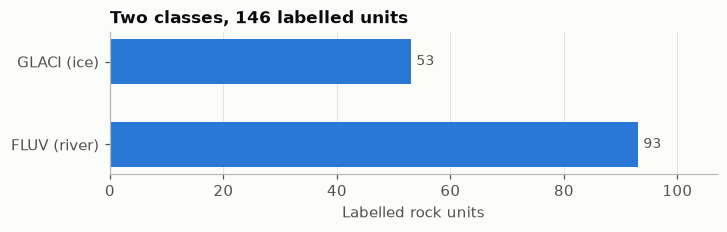

split,train,valid,test,total,share
class,,,,,
FLUV,59,15,19,93,63.7%
GLACI,35,8,10,53,36.3%


In [11]:
class_table = labels.pivot_table(index="class", columns="split", values="node", aggfunc="count")[["train", "valid", "test"]]
class_table["total"] = class_table.sum(axis=1)
class_table["share"] = (class_table["total"] / class_table["total"].sum()).map("{:.1%}".format)
train_mode = labels.loc[labels.split == "train", "class"].mode()[0]
print("Largest-class accuracy on validation:", f"{(labels.loc[labels.split == 'valid', 'class'] == train_mode).mean():.3f}")
print("Unit appears in more than one split:", labels["node"].duplicated().sum())
print("Themes of labelled units:", triples[triples.subject.isin(labels.node) & triples.predicate.str.endswith("hasTheme")].object.map(short).value_counts().to_dict())

totals = class_table["total"]
fig, ax = plt.subplots(figsize=(6.5, 2.0))
ax.barh(["FLUV (river)", "GLACI (ice)"], totals.values, color=plots.BLUE, height=0.55)
for yy, value in enumerate(totals.values):
    ax.text(value + 1, yy, f"{value}", va="center", color=plots.MUTED, fontsize=9)
ax.set(title="Two classes, 146 labelled units", xlabel="Labelled rock units")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, totals.max() * 1.15)
save(fig, "class_balance")
plt.show()
class_table

**Interpretation:** the task is small and fairly balanced: 93 FLUV and 53 GLACI, split 94 / 23 / 29 with the same class shares in each split. Always guessing FLUV scores 0.652 on validation, and macro F1 0.39. **With 23 validation and 29 test units, a single unit moves accuracy by 3–4 points**, so we compare methods with repeated cross-validation over the 117 training and validation units, never with one split. Almost all labelled units are superficial deposits (theme `SPRFCL`), so the task is about young sediments, not bedrock.

### Label leakage

The same checks as for dmg777k: is the target relation present, and do any graph features nearly determine the class? Purity is computed on the training split and checked on validation.

In [12]:
print("Triples using the target relation hasLithogenesis:", triples["predicate"].str.endswith("hasLithogenesis").sum())
print("Lithogenetic-type nodes linked to a labelled unit:",
      triples[triples.subject.isin(labels.node) & triples.object.str.contains("LithogeneticType")].shape[0])
labelled_rows = triples.merge(labels, left_on="subject", right_on="node")
train_rows = labelled_rows[labelled_rows["split"] == "train"]
pair_stats = train_rows.groupby(["predicate", "object"])["class"].agg(
    support="size", purity=lambda c: c.value_counts(normalize=True).iloc[0], top_class=lambda c: c.mode()[0]).reset_index()
pure = pair_stats[(pair_stats["support"] >= 5) & (pair_stats["purity"] >= 0.95)]
valid_rows = labelled_rows[labelled_rows["split"] == "valid"].merge(pure, on=["predicate", "object"])
valid_prediction = valid_rows.groupby("subject").agg(prediction=("top_class", lambda c: c.mode()[0]), truth=("class", "first"))
n_valid = (labels["split"] == "valid").sum()
print(f"Graph features with 95%+ purity in training (5+ units): {len(pure)}")
print(f"They apply to {len(valid_prediction)} of {n_valid} validation units; accuracy there: {(valid_prediction['prediction'] == valid_prediction['truth']).mean():.3f}")
view = pure.sort_values("support", ascending=False).head(10).copy()
view["predicate"] = view["predicate"].map(short)
view["object"] = view["object"].map(lambda o: short(o) if o.startswith("http") else o).str.slice(0, 50)
view["purity"] = view["purity"].round(3)
view.reset_index(drop=True)

Triples using the target relation hasLithogenesis: 0
Lithogenetic-type nodes linked to a labelled unit: 0


Graph features with 95%+ purity in training (5+ units): 8
They apply to 9 of 23 validation units; accuracy there: 0.889


,predicate,object,support,purity,top_class
0,hasOldestAge,QO,8,1.0,FLUV
1,hasPredominantAge,QO,8,1.0,FLUV
2,hasUpperBoundaryDefinition,Ground surface.,8,1.0,FLUV
3,broader,TV,8,1.0,FLUV
4,broader,TRVA,6,1.0,FLUV
5,broader,MNHD,6,1.0,FLUV
6,hasUpperBoundaryDefinition,At surface.,5,1.0,FLUV
7,broader,WOLS,5,1.0,GLACI


**Interpretation:** **the target is not leaked directly.** `hasLithogenesis` was removed for every unit, not only the labelled ones, and no labelled unit links to a lithogenetic type. But **the graph's structure says a lot about the class.** Eight features are pure in training, and they apply to 9 of 23 validation units with 8 correct. Some are ordinary graph facts: the parent unit (`broader`), and the age `QO`. Others are free-text values used as identical literals, such as an upper boundary of "Ground surface.". Walks can use all of these. This fits the published RDF2Vec accuracy of about 0.87 on BGS: much of the task can be solved without geography. So geography has to help on the units these features don't cover.

### Missing data

In [13]:
owners = triples[triples["object"].map(kinds).eq(bgs.WKT_KIND)]
owner_table = pd.crosstab(owners["subject"].map(bgs.entity_type), owners["predicate"].map(short))
display(owner_table)
labelled_set = set(labels["node"])
links = {
    "own WKT": owners["subject"].isin(labelled_set).sum(),
    "map units via hasLexicon": triples[triples.predicate.str.endswith("hasLexicon") & triples.object.isin(labelled_set)].object.nunique(),
    "a stratotype via hasStratotype": triples[triples.predicate.str.endswith("hasStratotype") & triples.subject.isin(labelled_set)].subject.nunique(),
}
print("Labelled units with:", links)
strat = triples[triples.predicate.str.endswith("hasStratotype")]
units = pd.Series(names)[pd.Series(names).str.contains("/id/Lexicon/NamedRockUnit/")]
mapped = set(triples.loc[triples.predicate.str.endswith("hasLexicon"), "object"])
print(f"All named rock units: {len(units):,}; with a stratotype: {strat.subject.nunique():,}; with a map unit: {len(mapped & set(units)):,}")
weak = graph.connected_components(mode="weak")
entity_components = graph.induced_subgraph(np.flatnonzero(is_entity)).connected_components(mode="weak")
print(f"Weakly connected components: {len(weak)}; entities only: {len(entity_components)}")

predicate,hasBoundingBox,hasFootprint,hasPointLocation,spatial
subject,,,,
625KGeologyMap/Dyke,0,3263,3263,3263
625KGeologyMap/Fault,0,2743,2743,2743
625KGeologyMap/Unit,0,11244,11244,11244
Lexicon/Stratotype,5534,5526,5534,5526


Labelled units with: {'own WKT': np.int64(0), 'map units via hasLexicon': 0, 'a stratotype via hasStratotype': 97}


All named rock units: 17,943; with a stratotype: 3,290; with a map unit: 154
Weakly connected components: 1; entities only: 1


**Interpretation:**

- **No labelled unit has a geometry of its own, and none is drawn on the map.** In dmg777k every monument had its own shape. Here a unit's location must be inherited. 97 units have a stratotype, which gives a precise site two hops away. The other 49 have nothing direct.
- **The map and the Lexicon barely meet.** 11,244 map units link to only 154 of the 17,943 named rock units, and to no labelled one. So the large polygons of the map reach the labelled units only through hubs.
- **3,290 rock units have a stratotype.** This makes a label-free test of flooding possible on thousands of units, not just the 146 with a class.
- **The graph is connected,** with and without literals, so every node gets some location.

## 4. Specific analysis, tied to our planned contributions

### Geometry quality

Geometry types: {'Polygon': 23917, 'Point': 21943, 'LineString': 2743}
Empty geometries in the triples: 2 ['POLYGON EMPTY']


Invalid geometries: 36   Centre range: lon -8.65 to 2.09, lat 49.86 to 60.86


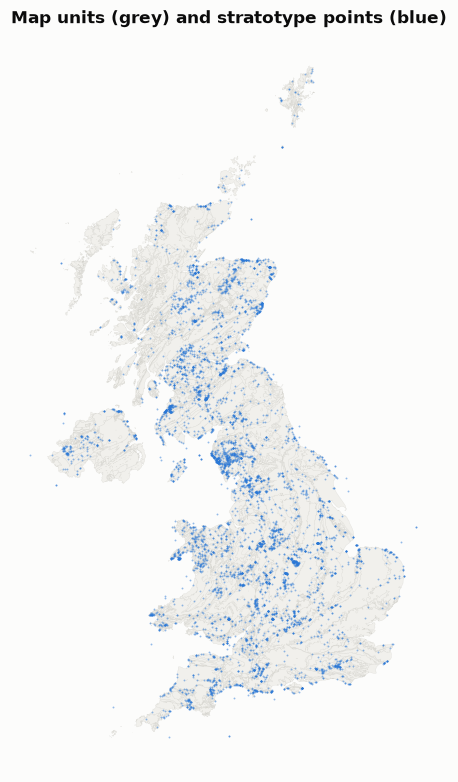

In [14]:
type_names = {0: "Point", 1: "LineString", 3: "Polygon"}
print("Geometry types:", pd.Series(shapely.get_type_id(geometries)).map(type_names).value_counts().to_dict())
empty_wkt = owners.loc[owners["object"].str.contains("EMPTY"), "object"]
print("Empty geometries in the triples:", len(empty_wkt), empty_wkt.unique().tolist())
centres = shapely.centroid(geometries)
cx, cy = shapely.get_x(centres), shapely.get_y(centres)
print(f"Invalid geometries: {(~shapely.is_valid(geometries)).sum()}   Centre range: lon {cx.min():.2f} to {cx.max():.2f}, lat {cy.min():.2f} to {cy.max():.2f}")

footprints = owners[owners["predicate"].str.endswith("hasFootprint") & owners["subject"].str.contains("625KGeologyMap/Unit")]
base = gpd.GeoDataFrame(geometry=sp.parse_geometries(footprints["object"]), crs=4326).simplify(0.003)
def draw_base(ax):
    base.plot(ax=ax, facecolor="#f1f0ec", edgecolor="#d5d4ce", linewidth=0.15, rasterized=True)
    ax.set_axis_off()
    ax.set_aspect(1.7)

strat_points = owners[owners["predicate"].str.endswith("hasPointLocation") & owners["subject"].str.contains("Stratotype")]
sg = sp.parse_geometries(strat_points["object"])
fig, ax = plt.subplots(figsize=(5.2, 7))
draw_base(ax)
ax.scatter(shapely.get_x(sg), shapely.get_y(sg), s=1.5, color=plots.BLUE, alpha=0.5, linewidths=0, rasterized=True)
ax.set_title("Map units (grey) and stratotype points (blue)")
save(fig, "map_all_geometries")
plt.show()

**Interpretation:** the geometries are usable. After reprojection all centres fall within the UK and its waters (8.65°W to 2.09°E, 49.9°N to 60.9°N). The map also covers Northern Ireland, not only Great Britain. 36 shapes are invalid, mostly self-touching polygons, which does not matter for centroids. Two stratotype footprints are empty. Stratotypes cover the whole country but cluster where rocks are well studied. The map units cover the land completely, so they double as a background map.

### Does location relate to the class?

This is the central assumption behind GeoRDF2Vec. We use two locations per unit: the repo's flooded centroid, available for all units, and the stratotype point, available for 97, as the best case. Scores come from a classifier that sees only coordinates, with 5-fold cross-validation repeated 20 times over the 117 training and validation units.

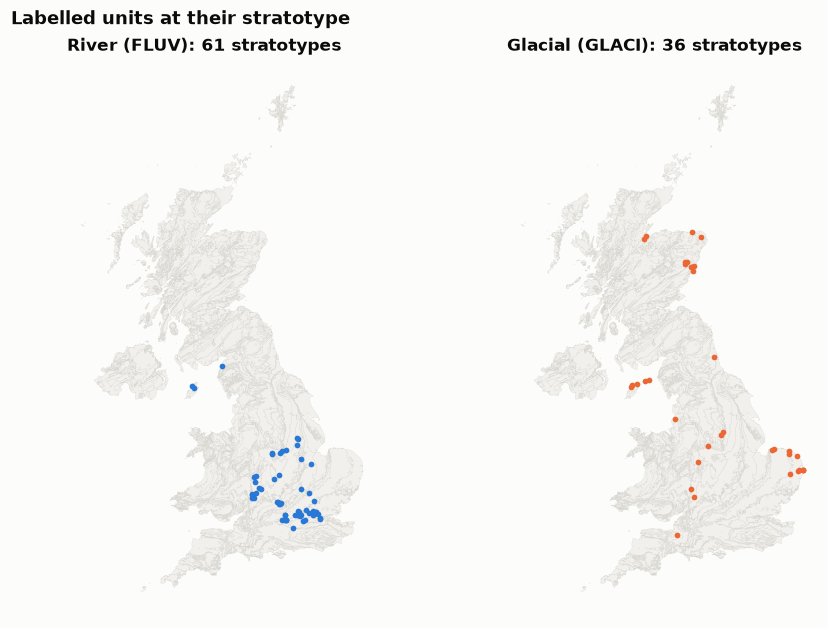

Stratotype latitude: FLUV median 51.81, GLACI median 53.47, Mann-Whitney p = 3.8e-10


class,FLUV,GLACI
lat,,
"(49, 52]",38,2
"(52, 54]",20,17
"(54, 56]",3,6
"(56, 61]",0,11


,Accuracy,Macro F1,Macro F1 sd
Always predict FLUV (n=117),0.632,0.387,0.000
"Nearest 3, repo's flooded centroid (n=117)",0.785,0.748,0.073
"Nearest 7, repo's flooded centroid (n=117)",0.776,0.719,0.083
"Nearest 15, repo's flooded centroid (n=117)",0.682,0.520,0.120
"Nearest 7, repo's flooded centroid, shuffled labels",0.582,0.471,0.112
"Nearest 3, stratotype point (n=77)",0.873,0.863,0.073
"Nearest 7, stratotype point (n=77)",0.880,0.866,0.076
"Nearest 15, stratotype point (n=77)",0.787,0.739,0.136
"Nearest 7, stratotype point, shuffled labels",0.553,0.471,0.168


In [15]:
strat_loc = (
    triples[triples.predicate.str.endswith("hasStratotype")][["subject", "object"]]
    .merge(strat_points.rename(columns={"subject": "object", "object": "wkt"})[["object", "wkt"]], on="object")
)
pts = sp.parse_geometries(strat_loc["wkt"])
strat_loc = strat_loc.assign(lon=shapely.get_x(pts), lat=shapely.get_y(pts)).groupby("subject")[["lon", "lat"]].mean()
located = labels.join(strat_loc, on="node")
located["flood_lon"], located["flood_lat"] = x[labelled_vertices], y[labelled_vertices]

fig, axes = plt.subplots(1, 2, figsize=(8, 5.6))
for ax, (class_id, title) in zip(axes, (("FLUV", "River (FLUV)"), ("GLACI", "Glacial (GLACI)"))):
    draw_base(ax)
    subset = located[(located["class"] == class_id) & located["lon"].notna()]
    ax.scatter(subset["lon"], subset["lat"], s=14, color=plots.BLUE if class_id == "FLUV" else plots.ORANGE, linewidths=0)
    ax.set_title(f"{title}: {len(subset)} stratotypes")
fig.suptitle("Labelled units at their stratotype", x=0.01, ha="left", fontweight="bold")
save(fig, "map_by_class")
plt.show()

a, b = located.loc[located["class"] == "FLUV", "lat"].dropna(), located.loc[located["class"] == "GLACI", "lat"].dropna()
print(f"Stratotype latitude: FLUV median {a.median():.2f}, GLACI median {b.median():.2f}, Mann-Whitney p = {mannwhitneyu(a, b).pvalue:.1e}")
display(pd.crosstab(pd.cut(located["lat"], [49, 52, 54, 56, 61]), located["class"]))

def knn_cv(X, y, k=7, shuffle=False):
    """Mean accuracy and macro F1 over 5-fold cross-validation repeated 20 times."""
    rng = np.random.default_rng(1)
    scores = []
    for train_idx, test_idx in RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=0).split(X, y):
        y_train = rng.permutation(y[train_idx]) if shuffle else y[train_idx]
        prediction = KNeighborsClassifier(n_neighbors=k).fit(X[train_idx], y_train).predict(X[test_idx])
        scores.append((accuracy_score(y[test_idx], prediction), f1_score(y[test_idx], prediction, average="macro")))
    scores = np.array(scores)
    return {"Accuracy": scores[:, 0].mean(), "Macro F1": scores[:, 1].mean(), "Macro F1 sd": scores[:, 1].std()}

dev = located[located["split"] != "test"]   # test labels stay unused
majority = (dev["class"] == "FLUV").mean()
results = {f"Always predict FLUV (n={len(dev)})": {"Accuracy": majority, "Macro F1": majority / (1 + majority), "Macro F1 sd": 0.0}}
for label, cols in (("repo's flooded centroid", ["flood_lon", "flood_lat"]), ("stratotype point", ["lon", "lat"])):
    sub = dev.dropna(subset=cols)
    X, yy = sub[cols].to_numpy(), sub["class"].to_numpy()
    for k in (3, 7, 15):
        results[f"Nearest {k}, {label} (n={len(sub)})"] = knn_cv(X, yy, k)
    results[f"Nearest 7, {label}, shuffled labels"] = knn_cv(X, yy, 7, shuffle=True)
pd.DataFrame(results).T.round(3)

**Interpretation: yes, strongly.** This is the main difference from dmg777k.

- **Glacial deposits lie in the north, river deposits in the south.** The median stratotype latitude is 53.5°N for GLACI against 51.8°N for FLUV (Mann–Whitney p = 4e-10). South of 52°N, 38 of 40 units are FLUV. North of 56°N, all 11 are GLACI. This matches the geological history: ice sheets covered the north, while most of southern England stayed ice-free.
- **Location alone nearly matches the published graph-based results.** With the stratotype point, nearest neighbours reach macro F1 0.87, against 0.47 for shuffled labels and 0.39 for always guessing FLUV.
- **The repo's flooded location loses much of that signal.** It reaches 0.72–0.75, and falls to 0.52 with 15 neighbours, because 49 units share one identical point (next sections).

The caveats are size and coverage. With 77–117 units the spread across folds is about ±0.08, and the stratotype result covers only units that have one.

### Which relations are spatial?

The same measurement as for dmg777k, with one difference: no labelled unit has its own geometry, so the groups are formed by the entities that do (map units, dykes, faults, stratotypes). For scale, such an entity lies a median of 248 km from the mean position. The second table shows, for each relation at the labelled units, how far apart its two ends are, using the flooded centroids.

Entities with their own geometry: {'625KGeologyMap/Unit': 11244, 'Lexicon/Stratotype': 5534, '625KGeologyMap/Dyke': 3263, '625KGeologyMap/Fault': 2743}
Baseline, distance of a located entity to the mean position: 248.4 km (median)


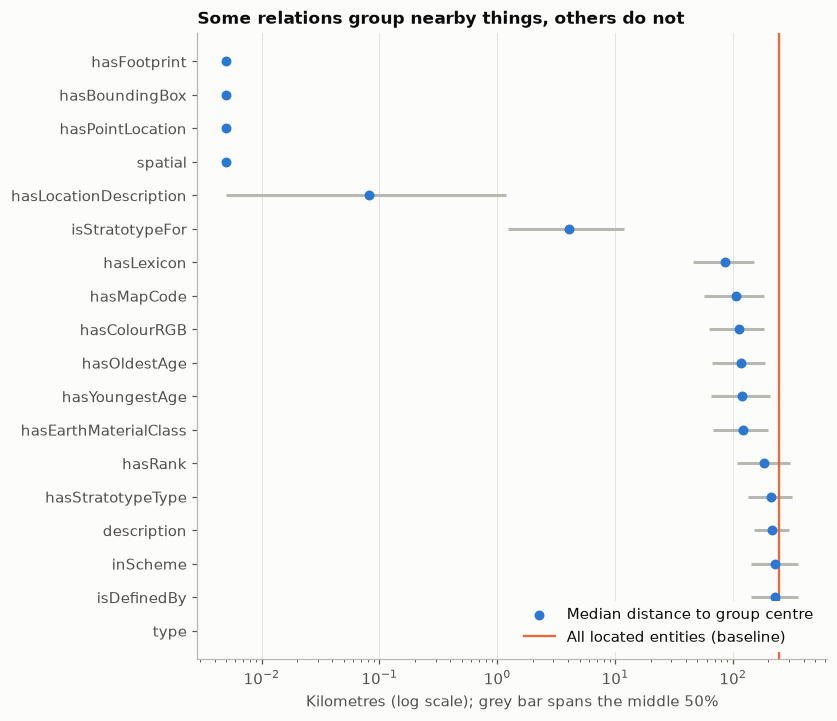

,edges,median,mean
relation,,,
altLabel,146,0.0,3.2
hasAdditionalAgeInformation,39,0.0,31.2
hasGeographicalDistribution,107,0.0,1.7
hasLithologyDescription,135,0.0,15.6
hasLowerBoundaryDefinition,105,0.0,3.0
hasObsoleteEquivalent,243,0.0,0.0
hasThicknessDescription,105,0.0,37.7
hasStratotype,132,0.0,2.6
identifier,146,0.0,0.0


,rows,groups,median
predicate,,,
hasPointLocation,1348,507,0.00
spatial,1316,491,0.00
hasFootprint,1316,491,0.00
hasBoundingBox,1344,505,0.00
hasLocationDescription,358,128,0.08
isStratotypeFor,3312,1264,4.05
hasLexicon,14499,146,85.28
hasMapCode,14506,109,105.96
hasColourRGB,14507,130,111.93


In [16]:
own = (flooded.hops == 1) & is_entity     # entities whose WKT is one hop away: map units, dykes, faults, stratotypes
own_names = pd.Series(names)[own].to_numpy()
own_x, own_y = pd.Series(x[own], index=own_names), pd.Series(y[own], index=own_names)
print("Entities with their own geometry:", pd.Series(own_names).map(bgs.entity_type).value_counts().to_dict())
baseline_km = np.median(sp.geodesic_km(own_x.to_numpy(), own_y.to_numpy(), np.full(len(own_x), own_x.mean()), np.full(len(own_x), own_y.mean())))
print(f"Baseline, distance of a located entity to the mean position: {baseline_km:.1f} km (median)")
dispersion = sp.relation_dispersion(triples, own_x, own_y, min_rows=100)
dispersion.index = dispersion.index.map(short)

ordered = dispersion.sort_values("median", ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 0.28 * len(ordered) + 1.4))
yy = np.arange(len(ordered))
ax.hlines(yy, ordered["q25"].clip(lower=0.005), ordered["q75"].clip(lower=0.005), color=plots.NEUTRAL, linewidth=2)
ax.scatter(ordered["median"].clip(lower=0.005), yy, s=30, color=plots.BLUE, zorder=3, label="Median distance to group centre")
ax.axvline(baseline_km, color=plots.ORANGE, linewidth=1.5, label="All located entities (baseline)")
ax.set_yticks(yy, ordered.index)
ax.set(xscale="log", xlabel="Kilometres (log scale); grey bar spans the middle 50%", title="Some relations group nearby things, others do not")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=True, framealpha=1, facecolor=plots.SURFACE, edgecolor="none")
save(fig, "relation_spatial_dispersion")
plt.show()

# Relations around the labelled units: how far apart are the two ends, using flooded centroids (correct axes)?
edge_predicates = pd.Series(graph.es["predicate"]).map(short)
around = np.isin(edges[:, 0], labelled_vertices) | np.isin(edges[:, 1], labelled_vertices)
display(pd.DataFrame({"relation": edge_predicates[around], "km": distance_true[around]}).groupby("relation")["km"]
        .agg(edges="size", median="median", mean="mean").query("edges >= 20").sort_values("median").round(1))
dispersion[["rows", "groups", "median"]].round(2)

**Interpretation:**

- **Spatial:** the geometry relations themselves, `hasLocationDescription` (80 m) and `isStratotypeFor` (4 km). A unit's stratotypes are close together.
- **Weakly spatial:** `hasLexicon` (85 km). Map units showing the same Lexicon entry are spread across a region. Many rock units occur in several places.
- **Not spatial:** colour, map code, ages, rank, `type`, `inScheme`, from 106 km to the 248 km baseline.

Around the labelled units, the second table says the same thing in another way. Labels, descriptions and `hasStratotype` connect nodes that share a location. Parent and child units (`broader`, `narrower`) are a median 44–59 km apart. Every schema relation (`type`, `inScheme`, `hasTheme`, ages, status) spans about 290 km, because its other end is a national-centroid hub. This gives relation-aware flooding a measured list of relations to keep and to drop.

### How far does flooding have to travel?

Round of labelled units: {np.int32(2): np.int64(97), np.int32(3): np.int64(49)}
Edges through which labelled units inherit their geometries: {'hasStratotype': 132, 'type': 49, 'broader': 13, 'narrower': 13}


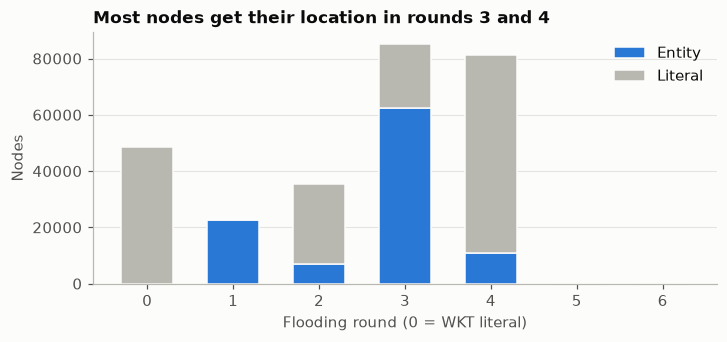

kind,Entity,Literal,Share of nodes
hop,,,
0,0,48603,17.7%
1,22784,0,8.3%
2,7036,28329,12.9%
3,62266,22785,31.0%
4,10874,70511,29.7%
5,95,514,0.2%
6,0,166,0.1%


In [17]:
hop_table = pd.DataFrame({"hop": flooded.hops, "kind": np.where(is_entity, "Entity", "Literal")}).value_counts().unstack(fill_value=0).sort_index()
hop_table["Share of nodes"] = (hop_table.sum(axis=1) / graph.vcount()).map("{:.1%}".format)
print("Round of labelled units:", dict(zip(*np.unique(flooded.hops[labelled_vertices], return_counts=True))))
inherit = Counter()
for v in labelled_vertices:
    for e in graph.incident(int(v), mode="all"):
        u = edges[e, 1] if edges[e, 0] == v else edges[e, 0]
        if flooded.hops[u] == flooded.hops[v] - 1:
            inherit[short(graph.es[e]["predicate"])] += 1
print("Edges through which labelled units inherit their geometries:", dict(inherit.most_common(6)))

fig, ax = plt.subplots(figsize=(6.5, 3))
bottom = np.zeros(len(hop_table))
for column, colour in (("Entity", plots.BLUE), ("Literal", plots.NEUTRAL)):
    ax.bar(hop_table.index, hop_table[column], bottom=bottom, color=colour, width=0.6, label=column, edgecolor=plots.SURFACE, linewidth=1)
    bottom += hop_table[column].to_numpy()
ax.set(xlabel="Flooding round (0 = WKT literal)", ylabel="Nodes", title="Most nodes get their location in rounds 3 and 4")
ax.grid(axis="x", visible=False)
ax.legend()
save(fig, "flooding_rounds")
plt.show()
hop_table

**Interpretation:**

- **Most nodes get their location in rounds 3 and 4** (61%), as in dmg777k. Round 1 holds the 22,784 entities that own a geometry.
- **The labelled units split into two groups.** 97 are reached in round 2 through `hasStratotype`. The other 49 are reached only in round 3, through `type → skos:Concept` and through parent and child units. Since `skos:Concept` has inherited every geometry by then, these 49 inherit everything too. Their own parents, which flooding also reaches in round 3, don't help.

### What locations do hubs inherit?

Nodes inheriting one geometry: 17.7%; more than 100: 139,911; all 48,603: 137,768 (50.3%)
Labelled units inheriting all geometries: 49 of 146 {'FLUV': 32, 'GLACI': 17}
Those nodes by kind: {'Language-tagged text': 70111, 'Entity (IRI)': 67202, 'Map code': 299, 'Number': 141}
Centroid of every such node: -3.327 55.398 (longitude, latitude)
Edges with one end at that centroid: 62.7%


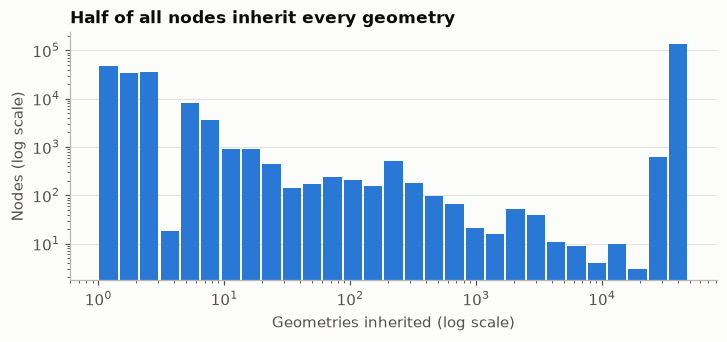

,node,kind,round,degree,geometries,median km to inherited geometries
0,http://www.w3.org/2004/02/skos/core#Concept,Entity (IRI),2,83024,48603,249.5
1,http://data.bgs.ac.uk/ref/Lexicon/NamedRockUnit,Entity (IRI),3,23404,42490,248.9
2,http://data.bgs.ac.uk/ref/625KGeologyMap/Unit,Entity (IRI),2,22493,22487,298.1
3,http://www.w3.org/1999/02/22-rdf-syntax-ns#nil,Entity (IRI),3,15235,26576,305.6
4,http://data.bgs.ac.uk/ref/CurrentStatus/CURRENT,Entity (IRI),3,12759,42490,248.9
5,http://data.bgs.ac.uk/id/EarthMaterialClass/ComponentRa,Entity (IRI),4,12729,48603,249.5
6,http://data.bgs.ac.uk/id/Lexicon/ShapeType/NotEntered,Entity (IRI),3,11682,48603,249.5
7,http://data.bgs.ac.uk/id/onshoreOffshore/ONSHORE,Entity (IRI),3,11101,40590,246.6
8,http://data.bgs.ac.uk/id/Lexicon/Theme/BEDRCK,Entity (IRI),3,10027,48603,249.5
9,http://data.bgs.ac.uk/id/Lexicon/SpatialScope/NotApplic,Entity (IRI),3,9209,48603,249.5


In [18]:
n_sources = flooded.n_sources
all_inherit = n_sources == len(seeds)
print(f"Nodes inheriting one geometry: {(n_sources == 1).mean():.1%}; more than 100: {(n_sources > 100).sum():,}; all {len(seeds):,}: {all_inherit.sum():,} ({all_inherit.mean():.1%})")
print("Labelled units inheriting all geometries:", f"{all_inherit[labelled_vertices].sum()} of {len(labels)}",
      labels.assign(c=all_inherit[labelled_vertices]).groupby("class")["c"].sum().to_dict())
print("Those nodes by kind:", pd.Series(node_kind[all_inherit]).value_counts().head(4).to_dict())
print("Centroid of every such node:", round(x[all_inherit][0], 3), round(y[all_inherit][0], 3), "(longitude, latitude)")
print("Edges with one end at that centroid:", f"{(all_inherit[edges[:, 0]] | all_inherit[edges[:, 1]]).mean():.1%}")

source_centres = shapely.centroid(geometries)
source_x, source_y = shapely.get_x(source_centres), shapely.get_y(source_centres)
def spread_km(vertex: int) -> float:
    members = flooded.sets[flooded.set_id[vertex]]
    return float(np.median(sp.geodesic_km(source_x[members], source_y[members], np.full(len(members), x[vertex]), np.full(len(members), y[vertex]))))

biggest = pd.DataFrame({"node": names, "kind": node_kind, "round": flooded.hops, "degree": total_degree, "geometries": n_sources})
biggest = biggest[is_entity & (n_sources > 1)].nlargest(10, "degree")
biggest["median km to inherited geometries"] = [round(spread_km(v), 1) for v in biggest.index]
biggest["node"] = biggest["node"].str.slice(0, 55)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(n_sources, bins=np.logspace(0, np.log10(n_sources.max() + 1), 30), color=plots.BLUE, rwidth=0.9)
ax.set(xscale="log", yscale="log", xlabel="Geometries inherited (log scale)", ylabel="Nodes (log scale)", title="Half of all nodes inherit every geometry")
ax.grid(axis="x", visible=False)
save(fig, "inherited_geometries")
plt.show()
biggest.reset_index(drop=True)

**Interpretation: the hub problem is much larger than in dmg777k.** **137,768 nodes (50.3%) inherit all 48,603 geometries**, against 18.5% in dmg777k. All of them sit at one point, 3.33°W 55.40°N, in southern Scotland. The point is not central to the labelled units, because the centroid of a geometry collection is weighted by area: the large map polygons of Scotland pull it north. 62.7% of edges touch one of these nodes. The cause is the same as in dmg777k, a class hub: `skos:Concept` collects every geometry in round 2 and passes it on. Other hubs (`NotEntered`, `Theme/BEDRCK`, the rock-unit class) do the same. For every hub in the table, the median inherited geometry is 250–300 km from the assigned point, so that location says nothing.

**Among the labelled units, this affects 49 of 146: 32 FLUV and 17 GLACI.** For dmg777k, relation-aware flooding could only move the nodes around the monuments. Here it can move the labelled units themselves.

### Does relation-aware flooding help?

A first test of our contribution, without training any embedding. We compare four ways of choosing which edges flooding may cross:

- **A:** the repo, all relations.
- **B:** all except `rdf:type`.
- **C:** all except edges at nodes with more than 1,000 edges.
- **D:** all except the schema and attribute relations that Section 4 found to be non-spatial: types, schemes, statuses, ages, ranks, colours, map codes.

Two scores:

- **Classification signal:** macro F1 of nearest neighbours on the flooded location, using cross-validation as above.
- **Hold-out:** for the 97 units with a stratotype, cut the unit–stratotype links, flood again, and measure how far the flooded location lands from the hidden stratotype. This is the paper's own kind of check (its Section 5.4) and needs no class labels.

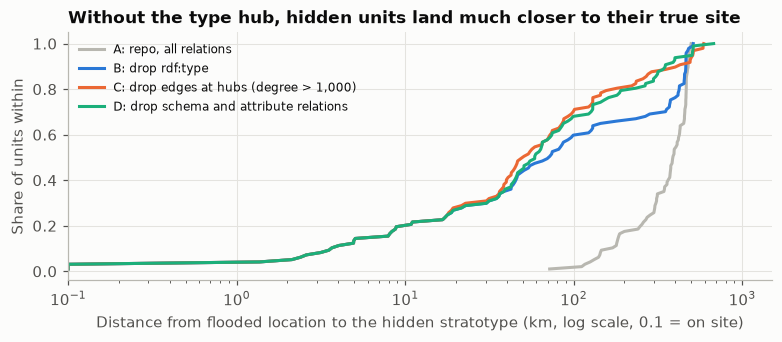

,Edges kept,All nodes at the GB centroid,Labelled units at the GB centroid,kNN macro F1 on flooded location,Hold-out: units placed,Hold-out: median error (km),Hold-out: within 25 km
"A: repo, all relations",100%,50.3%,49,0.719,97/97,388.9,0%
B: drop rdf:type,91%,0.0%,0,0.758,97/97,72.2,29%
"C: drop edges at hubs (degree > 1,000)",52%,0.0%,0,0.713,97/97,50.8,30%
D: drop schema and attribute relations,47%,0.0%,0,0.779,97/97,58.8,29%


In [19]:
predicates = edge_predicates.to_numpy()
SCHEMA = {"type", "inScheme", "isDefinedBy", "hasCurrentStatus", "hasTheme", "hasShapeType", "hasDefinitionStatus",
          "hasSpatialScopeOfDefinition", "isOnshoreOffshore", "hasFormality", "hasRevisionNumber", "hasRank",
          "hasRockUnitRank", "hasUnitClass", "hasComponentRank", "hasStratotypeType", "accessRights",
          "hasOldestAge", "hasYoungestAge", "hasPredominantAge", "hasEarthMaterialClass", "hasColourRGB", "hasMapCode",
          "isLocallyDominant", "hasRoleDescription", "sourceType", "hasSourceInfo", "isSourceInfoFor"}
variants = {
    "A: repo, all relations": np.ones(len(predicates), bool),
    "B: drop rdf:type": predicates != "type",
    "C: drop edges at hubs (degree > 1,000)": (total_degree[edges[:, 0]] <= 1000) & (total_degree[edges[:, 1]] <= 1000),
    "D: drop schema and attribute relations": ~np.isin(predicates, list(SCHEMA)),
}
# Hold-out: cut every unit-stratotype link of the labelled units, then ask where flooding puts them.
cut = np.isin(predicates, ["hasStratotype", "isStratotypeFor"]) & (np.isin(edges[:, 0], labelled_vertices) | np.isin(edges[:, 1], labelled_vertices))
has_truth = located["lon"].notna().to_numpy()
truth = located.loc[has_truth, ["lon", "lat"]].to_numpy()
dev_mask = (labels["split"] != "test").to_numpy()

def flood_subset(mask):
    sub = graph.subgraph_edges(np.flatnonzero(mask), delete_vertices=False)
    result = sp.flood(sub, seeds)
    return result, *sp.node_centroids(result, geometries)

rows, errors = {}, {}
for name, keep in variants.items():
    fl, fx, fy = flood_subset(keep)
    X = np.column_stack([fx[labelled_vertices], fy[labelled_vertices]])
    ok = dev_mask & ~np.isnan(X).any(axis=1)
    scores = knn_cv(X[ok], labels["class"].to_numpy()[ok])
    hl, hx, hy = flood_subset(keep & ~cut)
    v = labelled_vertices[has_truth]
    err = sp.geodesic_km(hx[v], hy[v], truth[:, 0], truth[:, 1])
    errors[name] = err
    rows[name] = {
        "Edges kept": f"{keep.mean():.0%}",
        "All nodes at the GB centroid": f"{(fl.n_sources == len(seeds)).mean():.1%}",
        "Labelled units at the GB centroid": int((fl.n_sources[labelled_vertices] == len(seeds)).sum()),
        "kNN macro F1 on flooded location": round(scores["Macro F1"], 3),
        "Hold-out: units placed": f"{np.isfinite(err).sum()}/{len(v)}",
        "Hold-out: median error (km)": round(float(np.nanmedian(err)), 1),
        "Hold-out: within 25 km": f"{np.mean(err <= 25):.0%}",
    }

fig, ax = plt.subplots(figsize=(7, 3))
for (name, err), colour in zip(errors.items(), (plots.NEUTRAL, plots.BLUE, plots.ORANGE, "#1baf7a")):
    values = np.sort(np.clip(err[np.isfinite(err)], 0.1, None))   # a few land on their site; show them at 0.1 km
    ax.plot(values, np.arange(1, len(values) + 1) / len(values), color=colour, label=name)
ax.set_xlim(0.1, 1500)
ax.set(xscale="log", xlabel="Distance from flooded location to the hidden stratotype (km, log scale, 0.1 = on site)", ylabel="Share of units within",
       title="Without the type hub, hidden units land much closer to their true site")
ax.legend(fontsize=8)
save(fig, "flooding_variants_holdout")
plt.show()
pd.DataFrame(rows).T

**Interpretation: yes, clearly, and without any training.**

- **Every variant removes the national-centroid problem.** 0% of nodes and no labelled unit end up at the centroid, against 50.3% and 49 with the repo.
- **Hidden units land much closer to their true site.** The repo places all 97 at the centroid, a median of 389 km away. B, C and D bring that to 51–72 km, with about 30% within 25 km. They reach them mainly through parent and child units.
- **The classification signal improves when non-spatial relations are dropped.** Macro F1 rises from 0.72 to 0.78 with D, and to 0.76 with B. C, which drops hubs by size alone, does not improve on the repo (0.71). So choosing relations by meaning beats a simple degree threshold.

The test has limits. The hold-out uses only the 97 labelled units with a stratotype; the 3,290 stratotypes in the whole Lexicon would give a much larger version, and the dmg777k notebook should get the same test. The variants are hand-made, and the gap to the stratotype point (0.87) shows there is room for a better rule. And this measures location only. Whether better flooding improves the embeddings, through better edge weights, still has to be shown by training.

### Do walks drift? Do they even get long enough?

The same simulation as for dmg777k, here 50 walks of up to 8 steps from each of the 146 labelled units. We add a variant that may follow edges in both directions, the option we discussed for adaptive walk length. Distances use the correct axis order.

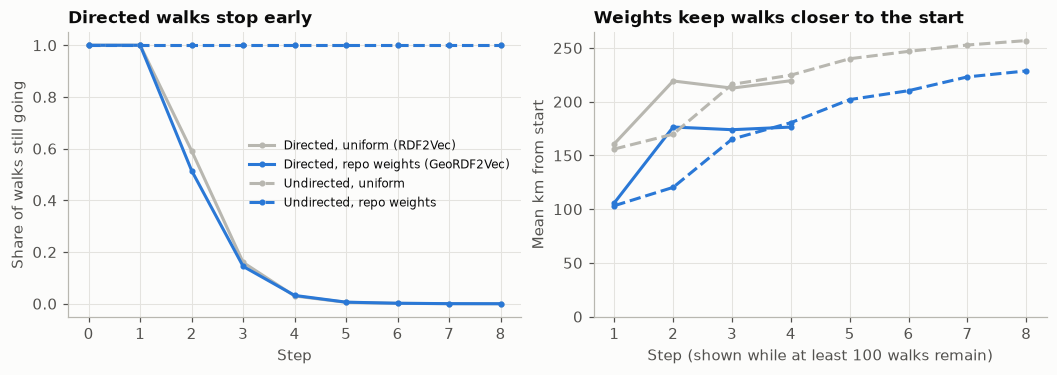

Mean km from start per step: {'Directed, uniform (RDF2Vec)': [np.float64(160.9), np.float64(219.3), np.float64(212.7), np.float64(219.5), None, None, None, None], 'Directed, repo weights (GeoRDF2Vec)': [np.float64(105.9), np.float64(176.4), np.float64(174.0), np.float64(176.4), None, None, None, None], 'Undirected, uniform': [np.float64(156.0), np.float64(169.8), np.float64(216.1), np.float64(224.7), np.float64(240.0), np.float64(246.8), np.float64(252.8), np.float64(256.9)], 'Undirected, repo weights': [np.float64(103.2), np.float64(120.3), np.float64(165.2), np.float64(180.5), np.float64(202.0), np.float64(210.3), np.float64(223.1), np.float64(228.6)]}


,"Directed, uniform (RDF2Vec)","Directed, repo weights (GeoRDF2Vec)","Undirected, uniform","Undirected, repo weights"
Mean steps taken (of 8),1.7878,1.6993,8.0000,8.0000
Walks reaching all 8 steps,0.0000,0.0000,1.0000,1.0000
Walks ending on a literal,0.6101,0.6560,0.1697,0.1719
Steps that are self-loops,0.0546,0.0631,0.0559,0.0647
Steps landing on a node already visited,0.0556,0.0637,0.2186,0.2593
Walks touching a GB-centroid node,0.5859,0.4912,0.9681,0.9089


In [20]:
rng = np.random.default_rng(7)
STEPS, WALKS, MIN_WALKS = 8, 50, 100
starts = labelled_vertices
walk_sets = {
    "Directed, uniform (RDF2Vec)": sp.simulate_walks(graph, starts, STEPS, None, WALKS, seed=1),
    "Directed, repo weights (GeoRDF2Vec)": sp.simulate_walks(graph, starts, STEPS, weight_repo, WALKS, seed=1),
    "Undirected, uniform": sp.simulate_walks(graph, starts, STEPS, None, WALKS, seed=1, undirected=True),
    "Undirected, repo weights": sp.simulate_walks(graph, starts, STEPS, weight_repo, WALKS, seed=1, undirected=True),
}
hub_nodes = all_inherit

def walk_summary(walks):
    lengths = np.array([len(w) - 1 for w in walks])
    alive = [(lengths >= step).mean() for step in range(STEPS + 1)]
    drift = []
    for step in range(1, STEPS + 1):
        pairs = np.array([(w[0], w[step]) for w in walks if len(w) > step])
        drift.append(np.mean(sp.geodesic_km(x[pairs[:, 0]], y[pairs[:, 0]], x[pairs[:, 1]], y[pairs[:, 1]])) if len(pairs) >= MIN_WALKS else np.nan)
    total_steps = max(lengths.sum(), 1)
    stats = {
        "Mean steps taken (of 8)": lengths.mean(),
        "Walks reaching all 8 steps": (lengths == STEPS).mean(),
        "Walks ending on a literal": np.mean([not is_entity[w[-1]] for w in walks]),
        "Steps that are self-loops": sum(a == b for w in walks for a, b in zip(w, w[1:])) / total_steps,
        "Steps landing on a node already visited": sum(len(w) - len(set(w)) for w in walks) / total_steps,
        "Walks touching a GB-centroid node": np.mean([hub_nodes[w[1:]].any() for w in walks]),
    }
    return alive, drift, stats

summaries = {name: walk_summary(w) for name, w in walk_sets.items()}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
styles = [(plots.NEUTRAL, "-"), (plots.BLUE, "-"), (plots.NEUTRAL, "--"), (plots.BLUE, "--")]
for (name, (alive, drift, _)), (colour, style) in zip(summaries.items(), styles):
    axes[0].plot(range(STEPS + 1), alive, color=colour, linestyle=style, marker="o", markersize=3, label=name)
    axes[1].plot(range(1, STEPS + 1), drift, color=colour, linestyle=style, marker="o", markersize=3, label=name)
axes[0].set(title="Directed walks stop early", xlabel="Step", ylabel="Share of walks still going")
axes[1].set(title="Weights keep walks closer to the start", xlabel=f"Step (shown while at least {MIN_WALKS} walks remain)", ylabel="Mean km from start")
axes[1].set_ylim(bottom=0)
axes[0].legend(fontsize=8)
save(fig, "walk_survival_and_drift")
plt.show()
print("Mean km from start per step:", {name: [None if np.isnan(v) else round(v, 1) for v in s[1]] for name, s in summaries.items()})
pd.DataFrame({name: s[2] for name, s in summaries.items()}).round(4)

**Interpretation:**

- **Directed walks are as short as in dmg777k.** They take about 1.7–1.8 steps out of 8, none reaches 8, and 61–66% end on a literal.
- **Undirected walks always reach 8 steps,** and 83% end on an entity. They also revisit nodes much more often (22–26% of steps), since they can step back.
- **Weights keep walks closer to the start in both settings.** Undirected weighted walks stay 28–53 km closer than uniform ones at every step, the gap shrinking with length: 103 against 156 km after one step, and 229 against 257 km after eight.
- **Hubs dominate the walks.** 49–59% of directed walks and 91–97% of undirected walks touch a national-centroid node. Those nodes are hubs, so a walk that enters one is effectively sent to a random part of the graph. Relation-aware flooding would change their weights. Excluding hubs from walks would be a separate decision.
- **Drift keeps growing with undirected walks** (from 156 to 257 km), unlike the plateau after step 2 in dmg777k. So on this graph the walk length setting actually changes what a walk sees, which is what adaptive walk length needs.

### What this means for our contributions

| Planned contribution | What BGS+ says | Compared with dmg777k | Suggested next step |
|---|---|---|---|
| Relation-aware flooding | **Strong support, effect measured.** It moves the labelled units themselves: hold-out error from 389 km to 51–72 km, location-only macro F1 from 0.72 to 0.78. | Much stronger: in dmg777k labelled monuments cannot move. | Turn rule D into a principled rule, for example keep relations whose dispersion is below the baseline. Run the hold-out on all 3,290 stratotypes, and add it to dmg777k. |
| Better aggregation | **Strong support.** 50.3% of nodes inherit every geometry, and that centroid sits in Scotland because of area weighting. | Same problem, larger (18.5% in dmg777k). | Keep. Compare an unweighted mean of centres and several locations per node. |
| Adaptive walk length | **Testable here.** Directed walks stop after about 1.7 steps, but undirected walks reach 8 and keep drifting. | dmg777k can only test it with undirected walks too. | Decide on walk direction first, then test length rules on both datasets. |
| Locality-aware walks | **Support.** Weights reduce drift by 28–53 km per step. Hubs are touched by most walks. | Same direction, larger distances. | Measure again after relation-aware flooding, since hubs then get real weights. |
| Coordinates as a feature | **Strong signal**: macro F1 0.87 from the stratotype point alone. | Much stronger (0.26 in dmg777k). | Keep as a baseline. On BGS+ it may be hard to beat. |

**On size:** with 146 labelled units, compare methods with repeated cross-validation and paired tests, and treat differences of a few points as noise. BGS+ complements dmg777k: dmg777k has many labels and weak location signal, BGS+ few labels and strong signal.
